# 108 · Multi-object decoders: any number of objects, and rotation
**Goal:** a decoder that draws every object in the scene (any count) *and* gets each one's rotation right, without losing CORE / HARD.
- s8-best-mag (one pose slot) nails rotation (rotated soap 17°), but finds both objects in only .36 of two-object scenes.
- s8-mag-nopose-r2 (no pose branch) finds both in .71, but rotation degrades to 27°.

| run | decoder | losses |
|---|---|---|
| s8-best-mag | direct + 1 pose slot (sum merge) | moment (single objects) + orient |
| s8-mag-nopose-r2 | direct conv decoder, one map | moment (single) + orient |
| s8-conv-mag-r2 | the original conv-conv model | mask only |
| s8-mag-nopose-imom-r2 | direct | **per-instance moment** (every object) |
| s8-mag-qpose-v3 | object queries (Mask2Former) + a pose head per query (detached soft-argmax centre) | per-instance moment + per-object angle |
| s8-mag-qpeak | qpose-v3 with two-stage queries: each starts at a peak of the direct map | as qpose |
| s8-mag-qonly | qpose-v3, each query mask = its warped canonical alone | as qpose |
| s8-mag-queries-r2 | object queries, no pose head | per-instance moment |
| s8-mag-centernet-r2 | centre heatmap, pose-branch mask + angle per peak | per-instance moment + per-object angle |
| s8-mag-qpose-os3 | qpose, two-object scenes 3× per epoch | as qpose |
| s8-mag-slots2-r3 | 2 pose slots (DETR matching) | moment + orient |

**Metrics.**
- **Two-object scenes** (two-cubes, cube-vase; 3 boxes; `src8/multi_object.py`). An object counts as *found* if more than 10% of it is covered at threshold .08. Also reported: *both / one / none* found, the union iou, *phantom* (a blob touching no object) and blobs per scene.
- **Goal metrics** (`src8/score.py`): CORE = 4 objects × 3 boxes; HARD = cardboard rotated soap; ALL = every eval split; iou / miss at .08.
- **Rotation:** principal-axis error in degrees on elongated objects. That is the rotated soap in HARD (the cubes and vases are near round, so two-object scenes can't measure it).

Runs that haven't finished are skipped. `NB108_RUNS` (comma-separated) overrides the list.

In [1]:
import os, sys, numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from pathlib import Path
from PIL import Image
ROOT = Path('..'); sys.path.insert(0, str(ROOT / 'src8'))
import score, multi_object
CAND = ['s8-best-mag-500ep', 's8-mag-nopose-r2-500ep', 's8-conv-mag-r2-500ep', 's8-mag-nopose-imom-r2-500ep', 's8-mag-qpose-v3-500ep', 's8-mag-qpeak-500ep', 's8-mag-qonly-500ep',
        's8-mag-queries-r2-500ep', 's8-mag-centernet-r2-500ep', 's8-mag-qpose-os3-500ep', 's8-mag-slots2-r3-500ep']
done = lambda r: any((ROOT / 'runs' / r / 'outputs_history/eval').rglob('ep0500-*.pt'))
RUNS = [r for r in (os.environ['NB108_RUNS'].split(',') if 'NB108_RUNS' in os.environ else CAND) if done(r)]
SHORT = {r: r.replace('s8-', '').replace('-500ep', '') for r in CAND}
PAL = ['#2a78d6', '#7a7a7a', '#b0b0b0', '#1baf7a', '#e34948', '#a3122f', '#f2a0a0', '#eb6834', '#8a5cd6', '#c8a2c8', '#d6a82a']
COL = dict(zip(CAND, PAL))                                         # fixed per run, never by rank
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .3})
print('runs:', [SHORT.get(r, r) for r in RUNS])

/home/ethantu/workspace/good-vibrations/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:1061: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()


runs: ['best-mag', 'mag-nopose-r2', 'conv-mag-r2', 'mag-nopose-imom-r2', 'mag-qpose-v3', 'mag-qpeak', 'mag-qonly', 'mag-queries-r2', 'mag-centernet-r2']


In [2]:
rows, MO = [], {}
for r in RUNS:
    ps = score.per_sample(r, 500, [0.08])
    s, _ = score.summarize(ps, ['iou@0.08', 'miss@0.08', 'orient_err@0.08', 'phantom@0.08'])
    mo = multi_object.scenes(r, 500); MO[r] = mo
    rows.append(dict(run=SHORT.get(r, r), **{f'{k} {m}': s.loc[k, f'{m}@0.08'] for k in ('CORE', 'HARD', 'ALL') for m in ('iou', 'miss')},
                     **{'HARD orient°': s.loc['HARD', 'orient_err@0.08'], 'both': mo.both.mean(), 'one': mo.one.mean(), 'none': mo.none.mean(),
                        'union iou': mo.iou.mean(), 'phantom': mo.phantom.mean(), 'blobs': mo.n_blobs.mean()}))
T = pd.DataFrame(rows).set_index('run')
T.round(3)

,CORE iou,CORE miss,HARD iou,HARD miss,ALL iou,ALL miss,HARD orient°,both,one,none,union iou,phantom,blobs
run,,,,,,,,,,,,,
best-mag,0.738,0.005,0.597,0.000,0.399,0.163,17.058,0.360,0.607,0.033,0.345,0.119,1.527
mag-nopose-r2,0.738,0.006,0.580,0.000,0.412,0.170,27.428,0.714,0.271,0.015,0.413,0.188,1.949
conv-mag-r2,0.626,0.031,0.434,0.048,0.327,0.234,35.513,0.446,0.426,0.128,0.275,0.461,2.089
mag-nopose-imom-r2,0.742,0.002,0.577,0.000,0.412,0.164,26.112,0.780,0.220,0.000,0.417,0.143,1.964
mag-qpose-v3,0.745,0.006,0.599,0.000,0.415,0.182,25.769,0.610,0.369,0.021,0.404,0.193,1.914
mag-qpeak,0.739,0.004,0.596,0.000,0.407,0.185,23.153,0.595,0.384,0.021,0.386,0.265,2.039
mag-qonly,0.728,0.007,0.564,0.000,0.389,0.195,26.159,0.518,0.402,0.080,0.315,0.345,1.935
mag-queries-r2,0.731,0.005,0.598,0.000,0.412,0.179,26.939,0.729,0.268,0.003,0.434,0.134,1.911
mag-centernet-r2,0.442,0.354,0.283,0.460,0.222,0.573,24.780,0.060,0.452,0.488,0.171,0.051,0.640


## 1 The trade-off: finding every object vs rotation
Upper left is the goal: both objects found in most scenes, and a small rotation error on the rotated soap.

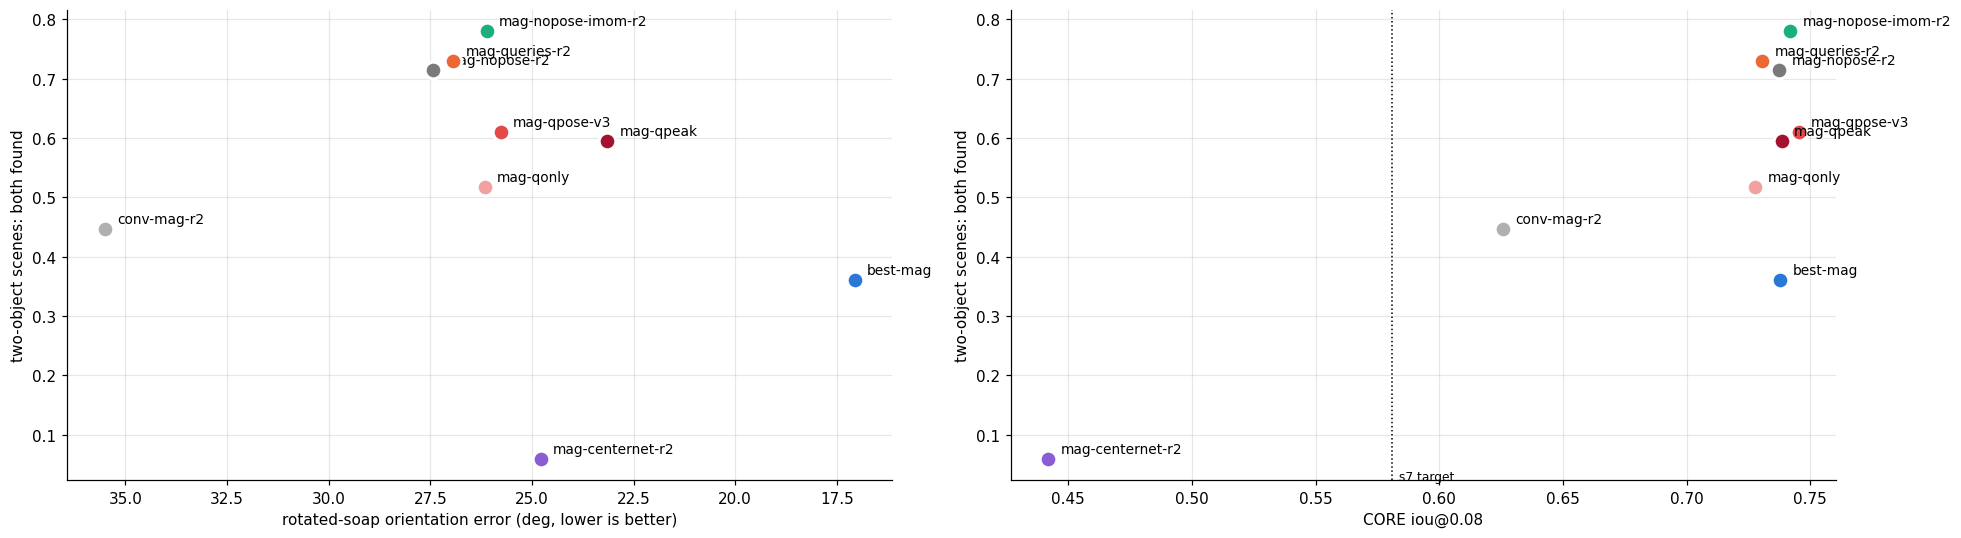

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(18, 5))
for r in RUNS:
    k = SHORT.get(r, r)
    ax[0].scatter(T.loc[k, 'HARD orient°'], T.loc[k, 'both'], s=120, color=COL.get(r, '#444'), zorder=3, edgecolor='white', linewidth=2)
    ax[0].annotate(k, (T.loc[k, 'HARD orient°'], T.loc[k, 'both']), xytext=(8, 4), textcoords='offset points', fontsize=9)
    ax[1].scatter(T.loc[k, 'CORE iou'], T.loc[k, 'both'], s=120, color=COL.get(r, '#444'), zorder=3, edgecolor='white', linewidth=2)
    ax[1].annotate(k, (T.loc[k, 'CORE iou'], T.loc[k, 'both']), xytext=(8, 4), textcoords='offset points', fontsize=9)
ax[0].set_xlabel('rotated-soap orientation error (deg, lower is better)'); ax[0].invert_xaxis()
ax[1].set_xlabel('CORE iou@0.08'); ax[1].axvline(0.581, color='k', ls=':', lw=1); ax[1].text(0.582, ax[1].get_ylim()[0], ' s7 target', fontsize=8)
for a in ax: a.set_ylabel('two-object scenes: both found')
plt.tight_layout()

## 2 Two-object scenes per box and pair type

best-mag  mag-nopose-r2  conv-mag-r2  \
box       types                                                       
cardboard green-cube+red-cube      0.12           0.69         0.20   
          red-cube+vase            0.42           0.62         0.36   
gastro    green-cube+red-cube      0.19           0.67         0.45   
          red-cube+vase            0.47           0.63         0.37   
plastic   green-cube+red-cube      0.50           0.77         0.66   
          red-cube+vase            0.57           0.98         0.82   

                               mag-nopose-imom-r2  mag-qpose-v3  mag-qpeak  \
box       types                                                              
cardboard green-cube+red-cube                0.76          0.45       0.49   
          red-cube+vase                      0.70          0.52       0.49   
gastro    green-cube+red-cube                0.74          0.57       0.62   
          red-cube+vase                      0.80          0.63       0.47   
plastic   green-cube+red-cube                0.81          0.72       0.72   
          red-cube+vase                      0.95          0.95       0.90   

                               mag-qonly  mag-queries-r2  mag-centernet-r2  
box       types                                                             
cardboard green-cube+red-cube       0.34            0.71              0.01  
          red-cube+vase             0.49            0.69              0.08  
gastro    green-cube+red-cube       0.40            0.67              0.12  
          red-cube+vase             0.50            0.70              0.00  
plastic   green-cube+red-cube       0.67            0.73              0.08  
          red-cube+vase             0.82            0.92              0.08

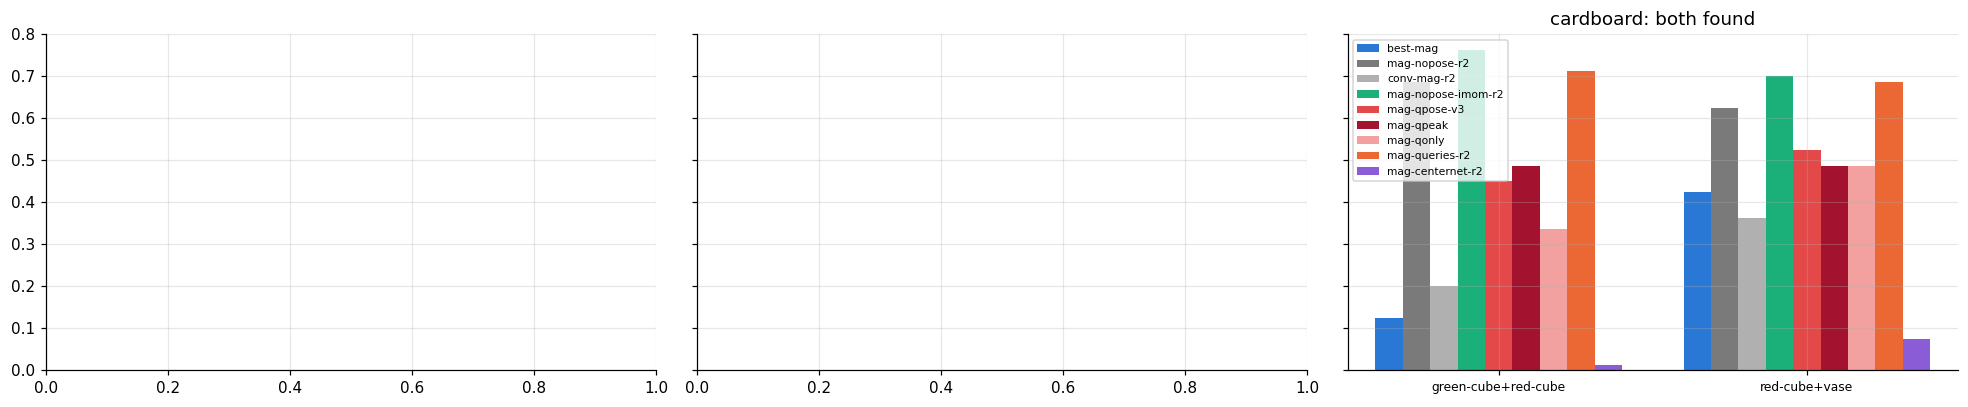

In [4]:
G = pd.concat({SHORT.get(r, r): MO[r].groupby(['box', 'types'])[['both', 'none', 'iou', 'phantom']].mean() for r in RUNS}, axis=1)
fig, ax = plt.subplots(1, 3, figsize=(18, 3.8), sharey=True)
for a, b in zip(ax, ['gastronorm', 'green-plastic', 'cardboard']):
    if b not in G.index.get_level_values(0): continue
    g = G.loc[b]; x, w = np.arange(len(g)), .8 / len(RUNS)
    for i, r in enumerate(RUNS): a.bar(x + i * w, g[(SHORT.get(r, r), 'both')], w, color=COL.get(r, '#444'), label=SHORT.get(r, r))
    a.set_xticks(x + .4 - w / 2, g.index, fontsize=8); a.set_title(f'{b}: both found')
ax[-1].legend(fontsize=7); plt.tight_layout()
G.xs('both', axis=1, level=1).round(2)

## 3 Gallery: two-object scenes
True instances (blue, orange outlines) and each run's mask at .08. The same 8 scenes for every run (fixed seed, spread over boxes and types).

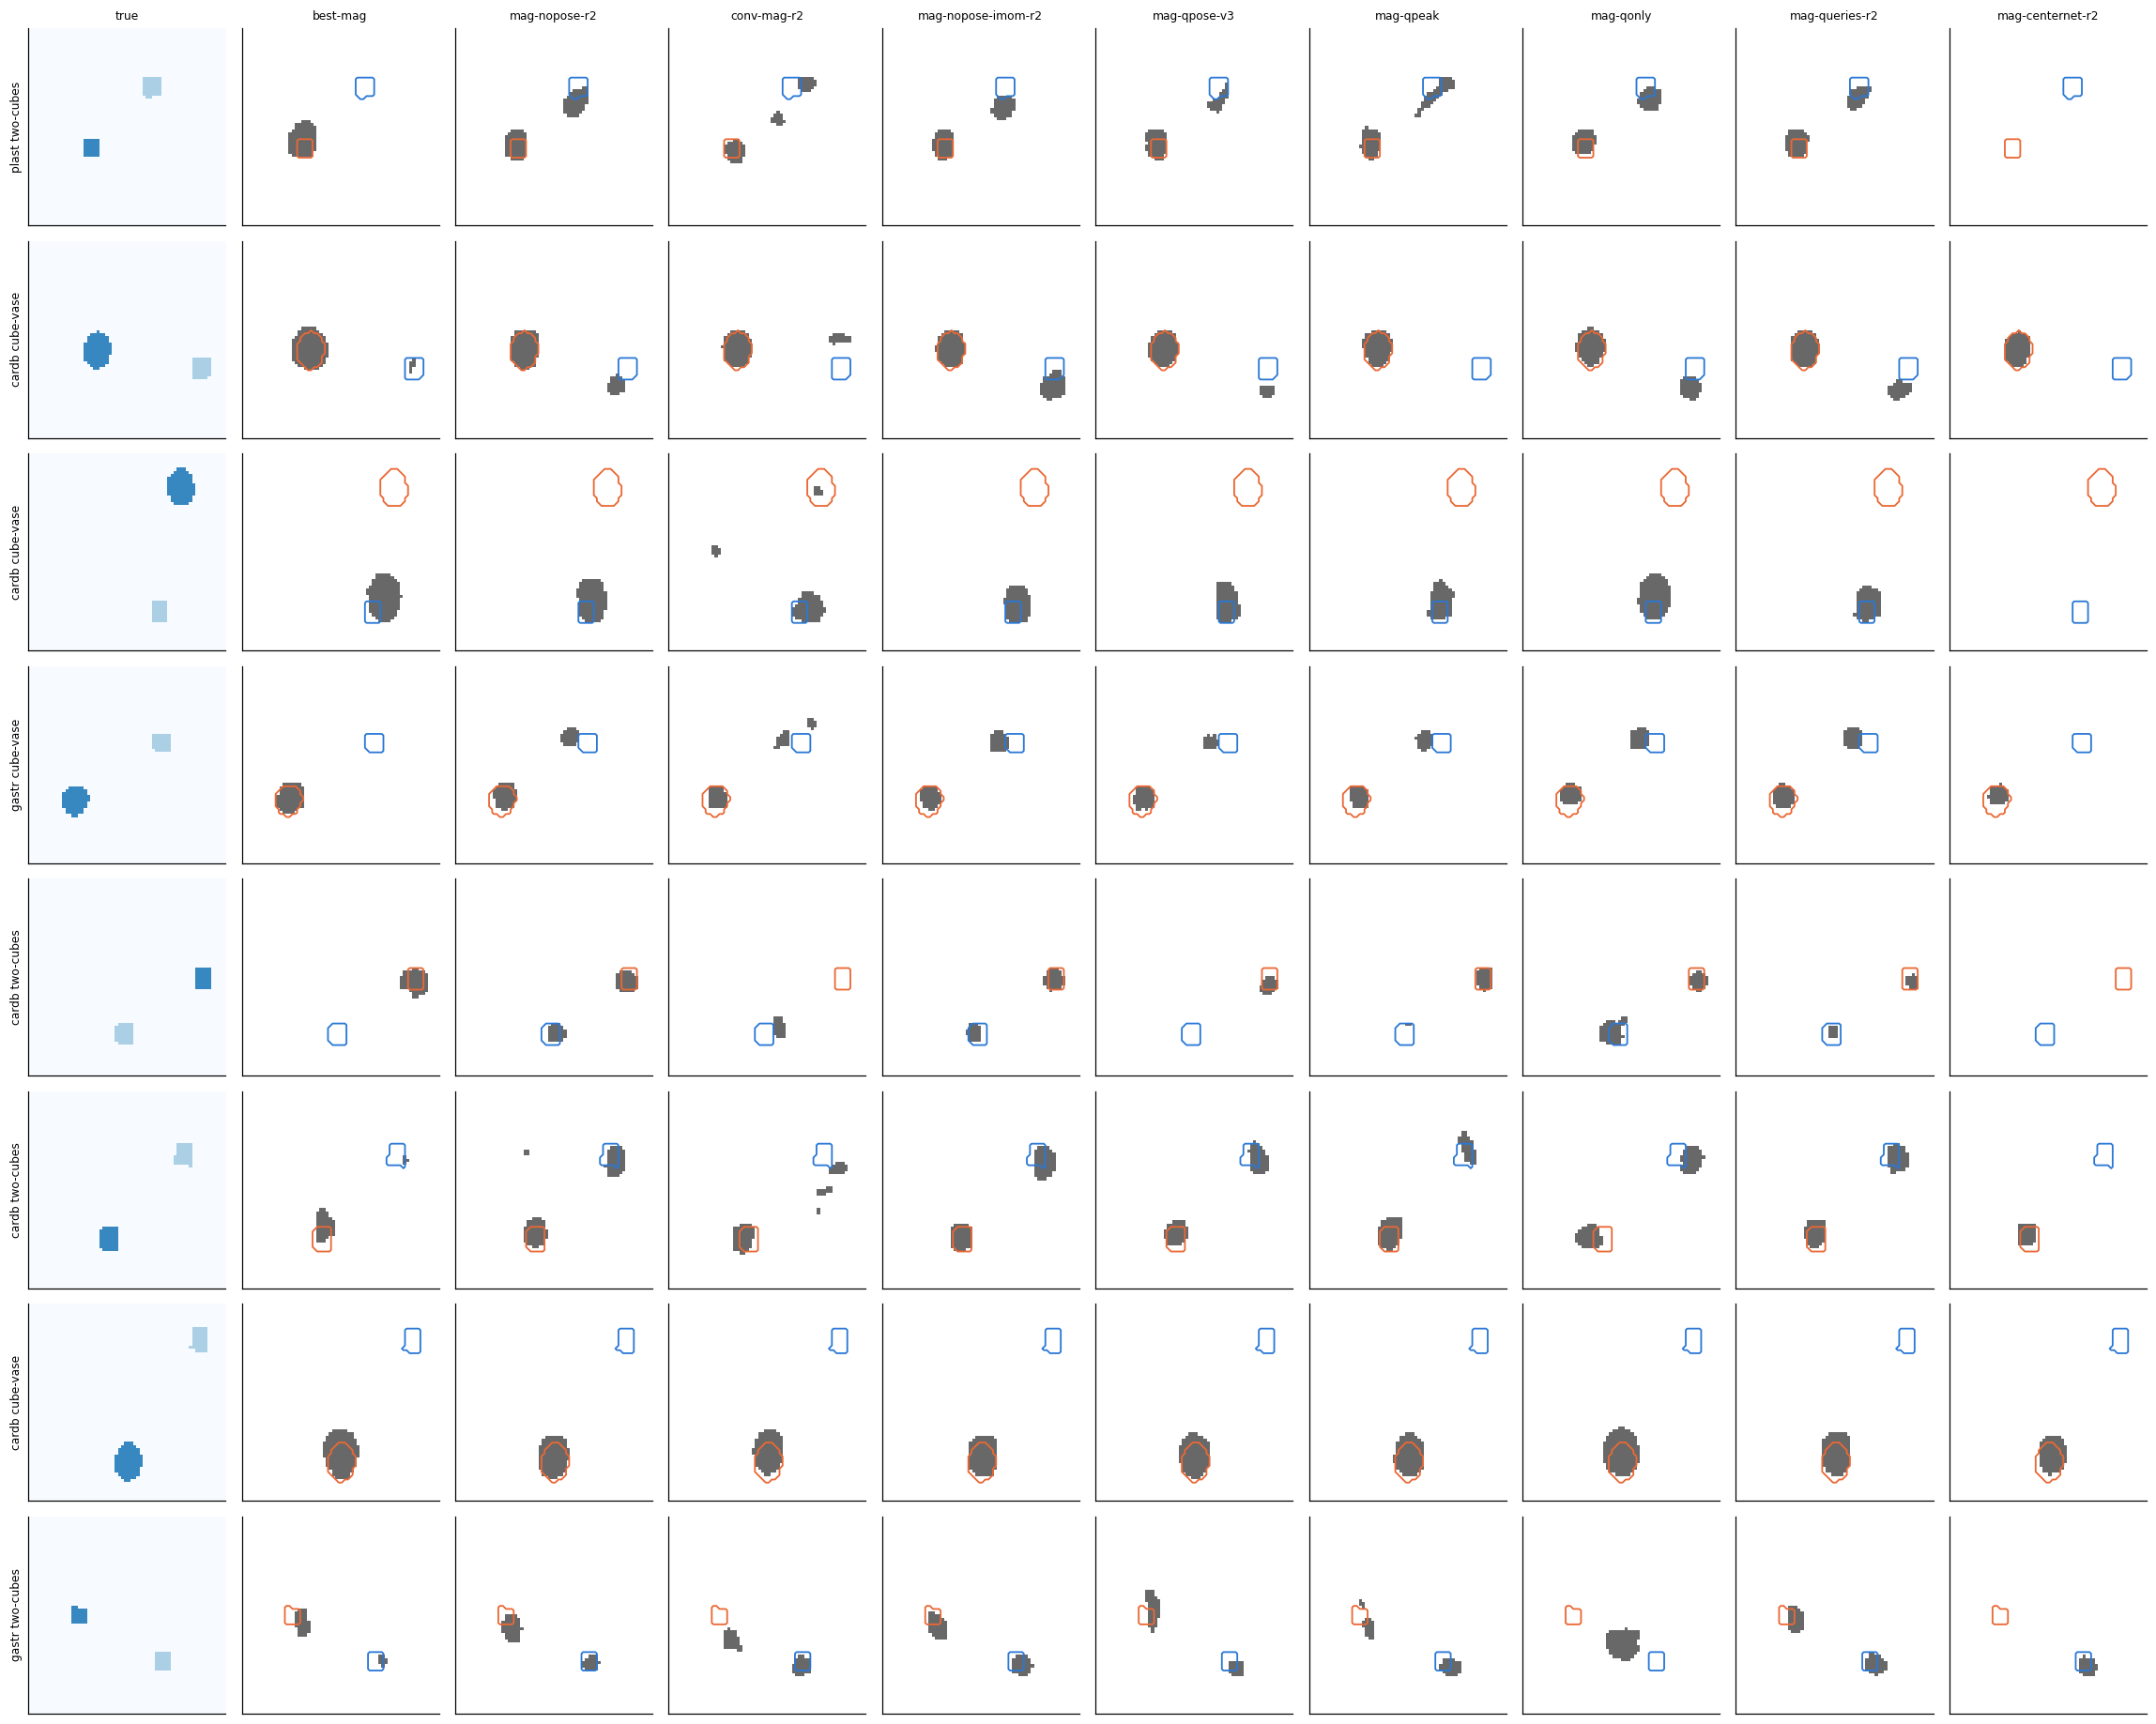

In [5]:
def preds(run, split_glob):
    out = {}
    for f in sorted((ROOT / 'runs' / run / 'outputs_history/eval').glob(f'{split_glob}/ep0500-ba*.pt')):
        d = torch.load(f, weights_only=False, map_location='cpu'); info = d['info']
        for i in range(len(d['mask_pred'])):
            out[(f.parent.parent.name, f.parent.name, info['experiment'][i], int(info['sample_id'][i]), int(info['position_id'][i]), int(info['speaker'][i]))] = d['mask_pred'][i].float().numpy()
    return out
P = {r: {**preds(r, '*/two-cubes'), **preds(r, '*/cube-vase')} for r in RUNS}
keys = sorted(set.intersection(*[set(p) for p in P.values()]))
rng = np.random.default_rng(0); pick = [keys[i] for i in rng.choice(len(keys), min(8, len(keys)), replace=False)]
fig, ax = plt.subplots(len(pick), len(RUNS) + 1, figsize=(2.1 * (len(RUNS) + 1), 2.1 * len(pick)))
for j, k in enumerate(pick):
    H, W = P[RUNS[0]][k].shape
    inst = [np.asarray(Image.fromarray((np.load(f) > 0).astype(np.float32)).resize((W, H), Image.BOX)) > .5 for f in sorted((score.sample_dir(*k[2:]) / 'image/smasks').glob('*.npy'))]
    ax[j, 0].imshow(sum((i + 1) * m for i, m in enumerate(inst)), cmap='Blues', vmin=0, vmax=3); ax[j, 0].set_ylabel(f'{k[0][:5]} {k[1]}', fontsize=8)
    for c, r in enumerate(RUNS):
        a = ax[j, c + 1]; a.imshow(P[r][k] > 0.08, cmap='Greys', vmin=0, vmax=1.5)
        for m, col in zip(inst, ('#2a78d6', '#eb6834')): a.contour(m, levels=[.5], colors=col, linewidths=1.2)
        if j == 0: a.set_title(SHORT.get(r, r), fontsize=8)
for a in ax.flat: a.set_xticks([]); a.set_yticks([]); a.grid(False)
ax[0, 0].set_title('true', fontsize=8); plt.tight_layout()

## 4 Gallery: the rotated soap (HARD), where rotation shows

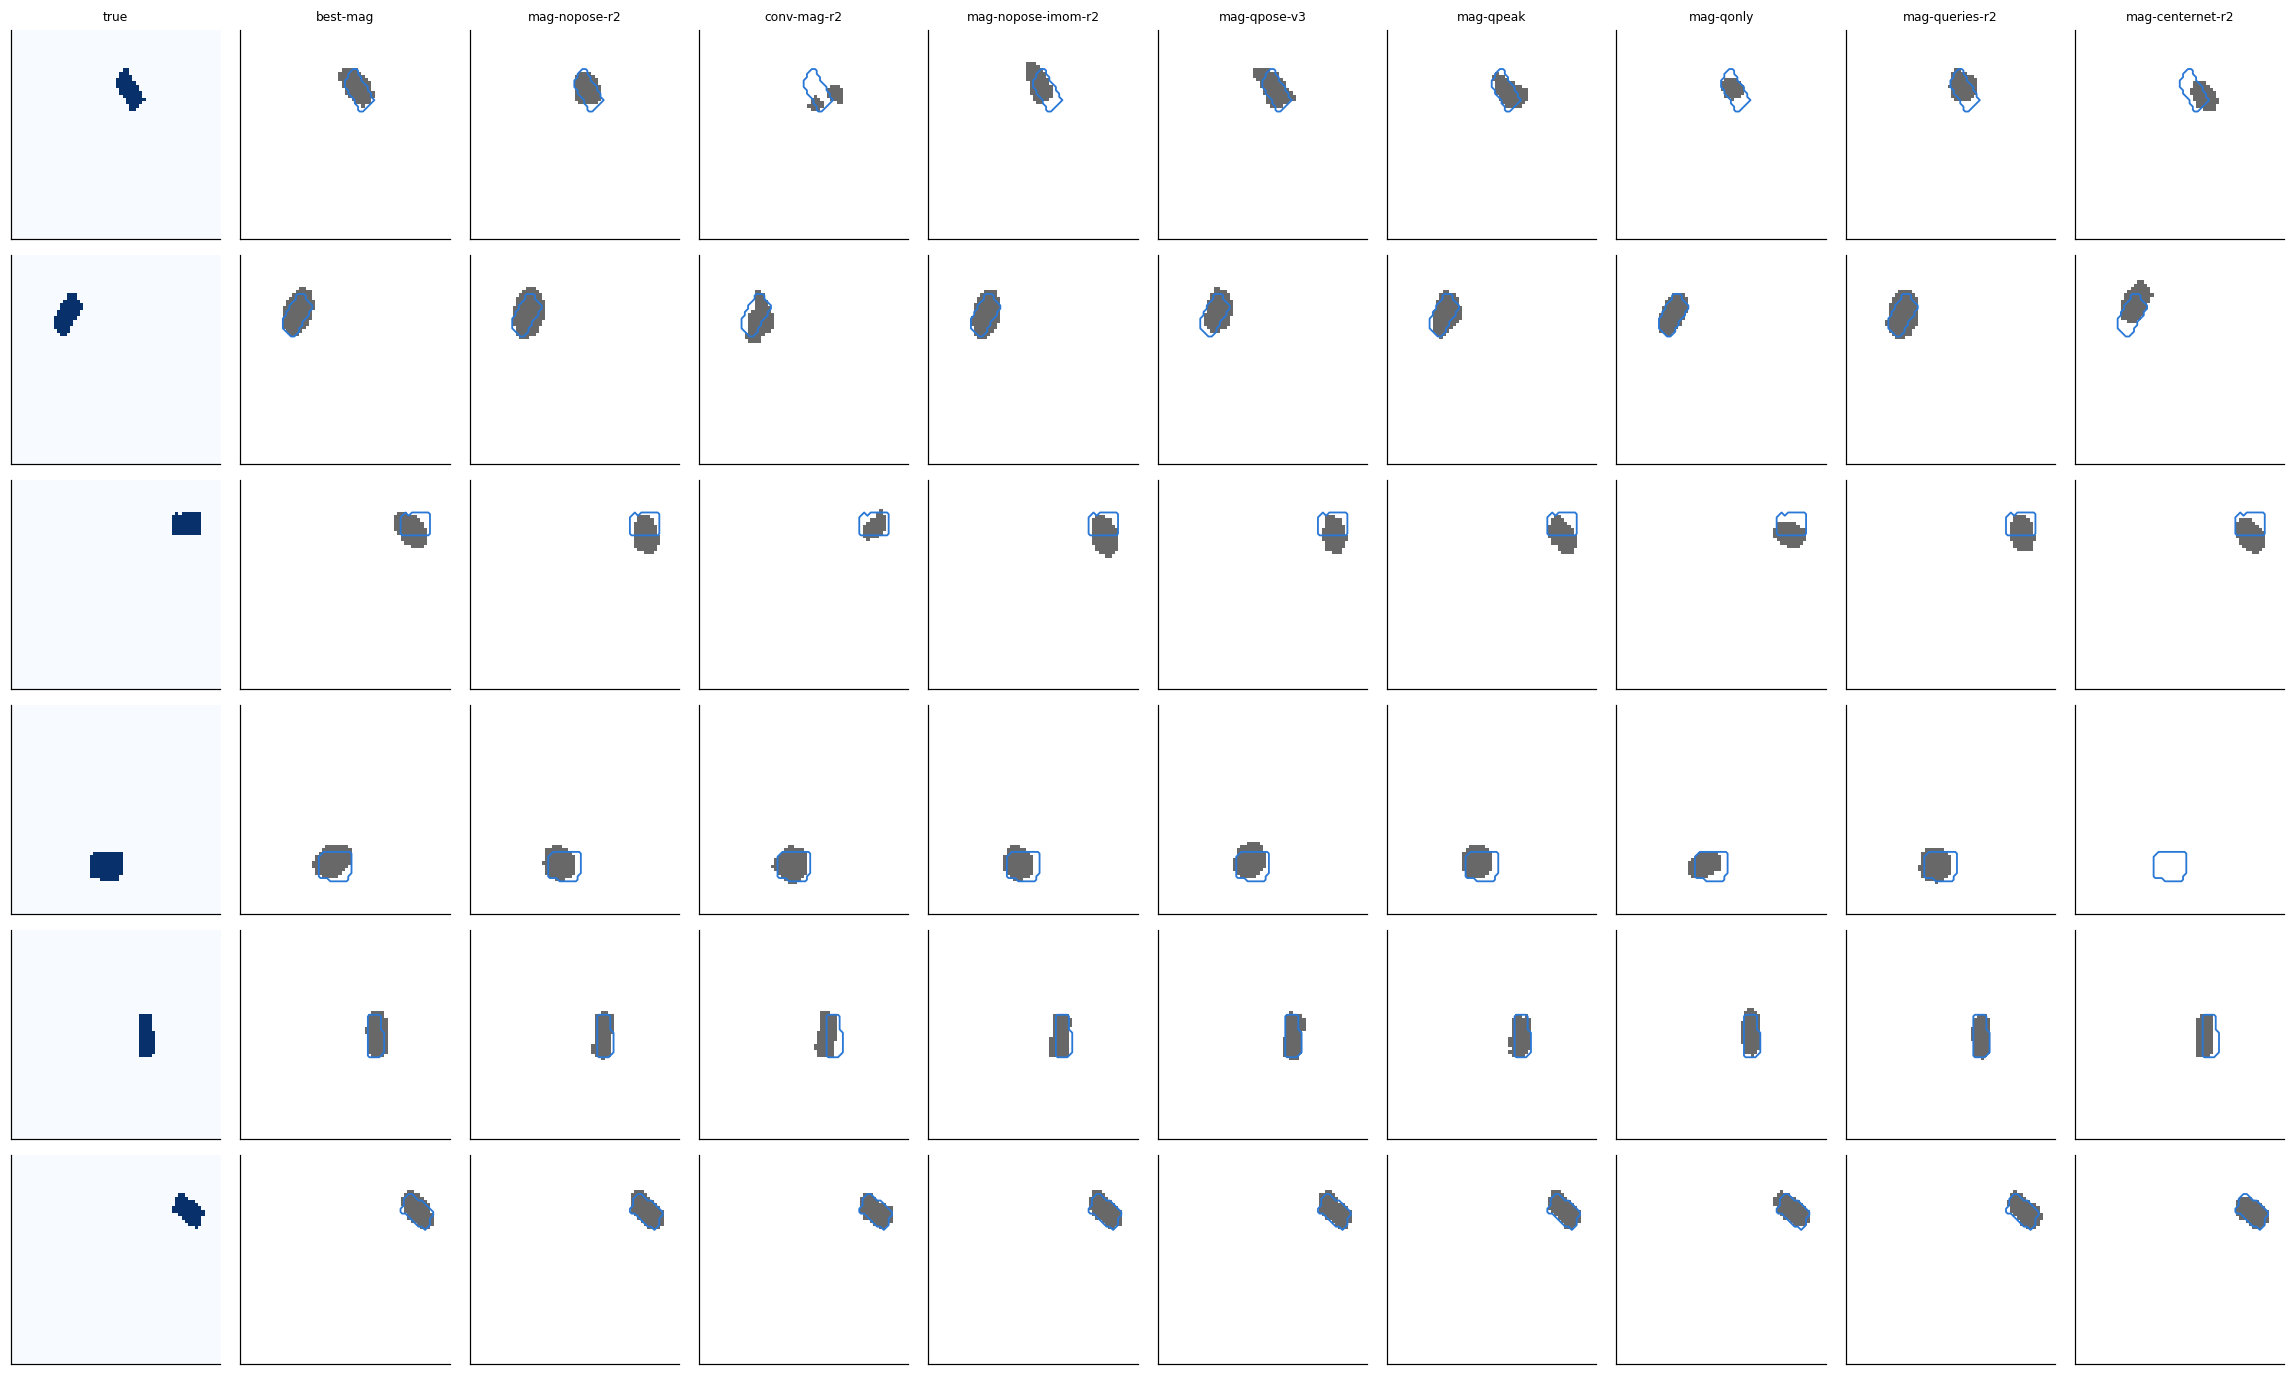

In [6]:
R = {r: preds(r, 'cardboard/soap-dispenser-rotated') for r in RUNS}
keys = sorted(set.intersection(*[set(p) for p in R.values()]))
pick = [keys[i] for i in np.random.default_rng(1).choice(len(keys), min(6, len(keys)), replace=False)]
fig, ax = plt.subplots(len(pick), len(RUNS) + 1, figsize=(2.1 * (len(RUNS) + 1), 2.1 * len(pick)))
for j, k in enumerate(pick):
    H, W = R[RUNS[0]][k].shape
    y = score.truth(*k[2:], H, W) > .5
    ax[j, 0].imshow(y, cmap='Blues')
    for c, r in enumerate(RUNS):
        a = ax[j, c + 1]; a.imshow(R[r][k] > 0.08, cmap='Greys', vmin=0, vmax=1.5); a.contour(y, levels=[.5], colors='#2a78d6', linewidths=1.2)
        if j == 0: a.set_title(SHORT.get(r, r), fontsize=8)
for a in ax.flat: a.set_xticks([]); a.set_yticks([]); a.grid(False)
ax[0, 0].set_title('true', fontsize=8); plt.tight_layout()

## 5 Verdict
_filled in as the runs finish_